# Adult Stroke Risk Prediction Using Lifestyle and Clinical Factors
**Models:** Logistic Regression, Random Forest, LightGBM  

## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve,
                             ConfusionMatrixDisplay)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load Dataset

In [2]:
# Change the path if your file is in a different location
DATA_PATH = "adult_stroke_lifestyle_clinical_dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (5110, 10)


,gender,age,hypertension,heart_disease,work_type,avg_glucose_level,bmi,bmi_missing,smoking_status,stroke
0,Male,67.0,0,1,Private,228.69,36.6,0,formerly smoked,1
1,Female,61.0,0,0,Self-employed,202.21,28.1,1,never smoked,1
2,Male,80.0,0,1,Private,105.92,32.5,0,never smoked,1
3,Female,49.0,0,0,Private,171.23,34.4,0,smokes,1
4,Female,79.0,1,0,Self-employed,174.12,24.0,0,never smoked,1


## 3. Data Understanding

In [3]:
df.info()
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   str    
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   work_type          5110 non-null   str    
 5   avg_glucose_level  5110 non-null   float64
 6   bmi                5110 non-null   float64
 7   bmi_missing        5110 non-null   int64  
 8   smoking_status     5110 non-null   str    
 9   stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(3)
memory usage: 399.3 KB

Missing values:
 gender               0
age                  0
hypertension         0
heart_disease        0
work_type            0
avg_glucose_level    0
bmi                  0
bmi_missing          0
smoking_status       0
stroke               0
dtype: int64

Duplic

,count,mean,std,min,25%,50%,75%,max
age,5110.0,43.226614,22.612647,0.08,25.000,45.000,61.00,82.00
hypertension,5110.0,0.097456,0.296607,0.00,0.000,0.000,0.00,1.00
heart_disease,5110.0,0.054012,0.226063,0.00,0.000,0.000,0.00,1.00
avg_glucose_level,5110.0,106.147677,45.283560,55.12,77.245,91.885,114.09,271.74
bmi,5110.0,28.862035,7.699562,10.30,23.800,28.100,32.80,97.60
bmi_missing,5110.0,0.039335,0.194409,0.00,0.000,0.000,0.00,1.00
stroke,5110.0,0.048728,0.215320,0.00,0.000,0.000,0.00,1.00


In [4]:
for col in ["gender", "work_type", "smoking_status", "hypertension", "heart_disease", "bmi_missing"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(), "\n")

--- gender ---
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64 

--- work_type ---
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64 

--- smoking_status ---
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64 

--- hypertension ---
hypertension
0    4612
1     498
Name: count, dtype: int64 

--- heart_disease ---
heart_disease
0    4834
1     276
Name: count, dtype: int64 

--- bmi_missing ---
bmi_missing
0    4909
1     201
Name: count, dtype: int64 



## 4. Exploratory Data Analysis

### 4.1 Target distribution (class imbalance)

stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


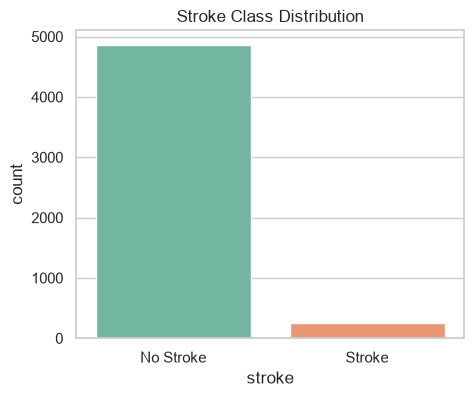

In [5]:
counts = df["stroke"].value_counts()
print(counts)
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x="stroke", data=df, palette="Set2")
plt.title("Stroke Class Distribution")
plt.xticks([0, 1], ["No Stroke", "Stroke"])
plt.show()

### 4.2 Numerical features vs stroke

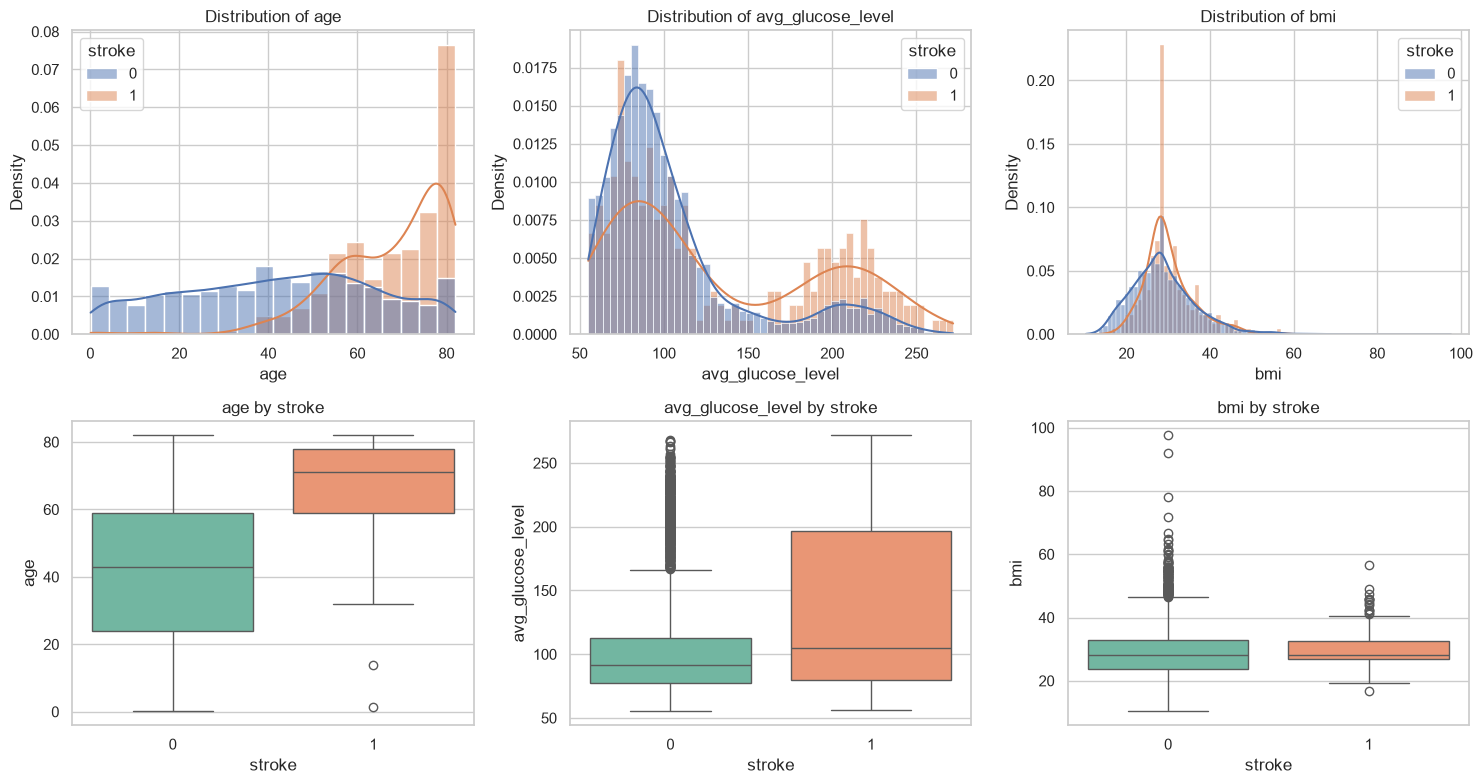

In [6]:
num_cols = ["age", "avg_glucose_level", "bmi"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(num_cols):
    sns.histplot(data=df, x=c, hue="stroke", kde=True, ax=axes[0, i], stat="density", common_norm=False)
    axes[0, i].set_title(f"Distribution of {c}")
    sns.boxplot(data=df, x="stroke", y=c, ax=axes[1, i], palette="Set2")
    axes[1, i].set_title(f"{c} by stroke")
plt.tight_layout()
plt.show()

### 4.3 Categorical features vs stroke rate

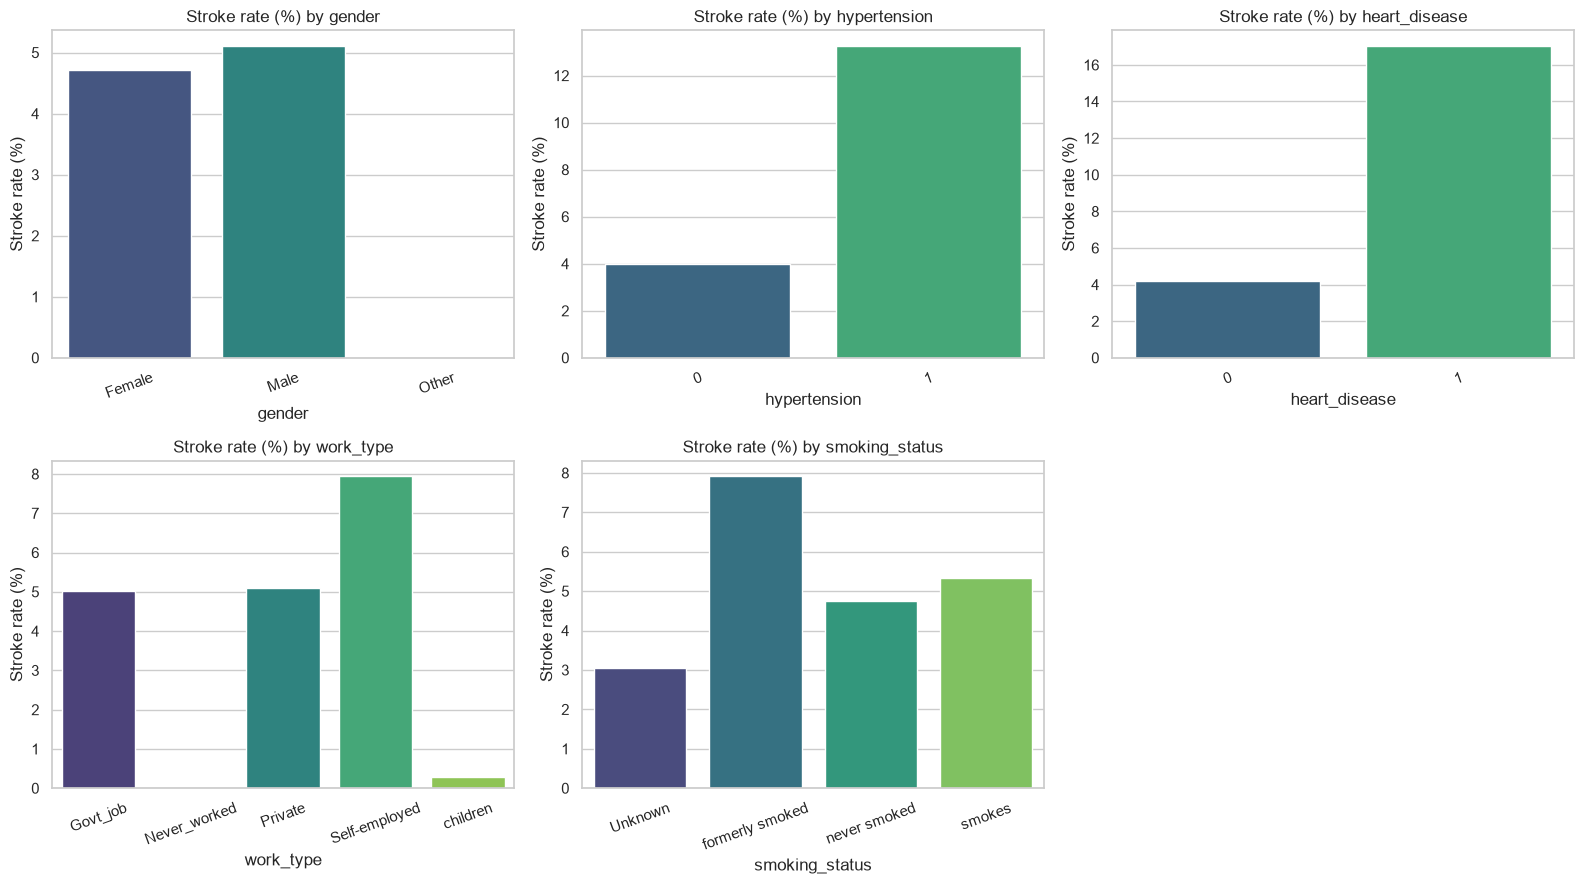

In [7]:
cat_plot = ["gender", "hypertension", "heart_disease", "work_type", "smoking_status"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
for i, c in enumerate(cat_plot):
    rate = df.groupby(c)["stroke"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=axes[i], palette="viridis")
    axes[i].set_title(f"Stroke rate (%) by {c}")
    axes[i].set_ylabel("Stroke rate (%)")
    axes[i].tick_params(axis="x", rotation=20)
axes[-1].axis("off")
plt.tight_layout()
plt.show()

### 4.4 Correlation heatmap

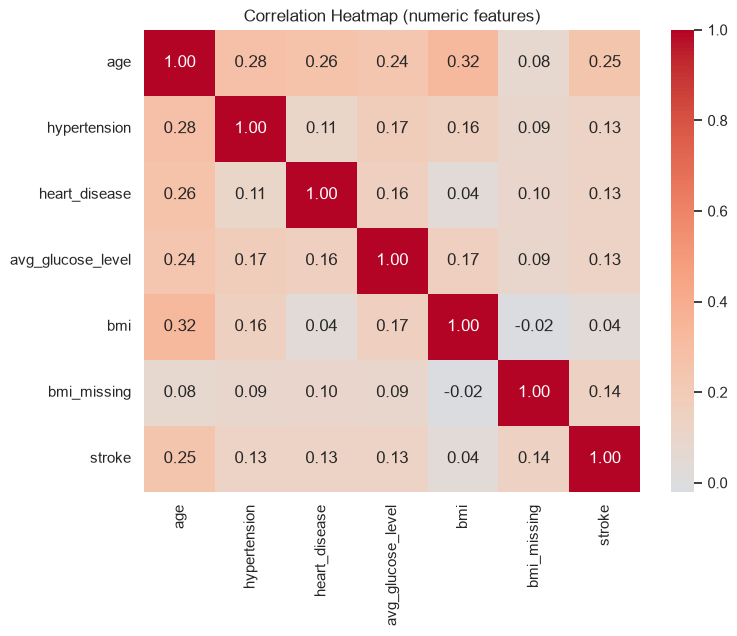

In [8]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (numeric features)")
plt.show()

## 5. Preprocessing

In [9]:
data = df.copy()

# 'Other' gender has very few records -> check and handle
print(data["gender"].value_counts())
data = data[data["gender"] != "Other"].reset_index(drop=True)

X = data.drop(columns="stroke")
y = data["stroke"]

cat_features = ["gender", "work_type", "smoking_status"]
num_features = ["age", "avg_glucose_level", "bmi"]
bin_features = ["hypertension", "heart_disease", "bmi_missing"]
print("\nFeature matrix:", X.shape)

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Feature matrix: (5109, 9)


### 5.1 Train / test split 

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Stroke rate:", round(y_train.mean() * 100, 2), "%")
print("Test :", X_test.shape,  "| Stroke rate:", round(y_test.mean() * 100, 2), "%")

Train: (4087, 9) | Stroke rate: 4.87 %
Test : (1022, 9) | Stroke rate: 4.89 %


### 5.2 Preprocessor and pipelines

In [11]:
from sklearn.preprocessing import OrdinalEncoder

# Column order used by all pipelines
feature_order = cat_features + bin_features + num_features
X_train = X_train[feature_order]
X_test = X_test[feature_order]

# Step 1: ordinal-encode categoricals (so SMOTENC can work on numbers)
ordinal_step = ColumnTransformer(
    [("ord", OrdinalEncoder(), cat_features)],
    remainder="passthrough", verbose_feature_names_out=False
).set_output(transform="pandas")

# After ordinal step the column order is: cat_features + bin_features + num_features
n_cat = len(cat_features)
n_bin = len(bin_features)
smote_cat_idx = list(range(n_cat + n_bin))   # categorical + binary columns

# Step 2: one-hot encode categoricals / scale numerics for the final model
def make_final_encoder(scale=True):
    num_tf = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", drop=None),
         list(range(n_cat))),
        ("num", num_tf, list(range(n_cat + n_bin, n_cat + n_bin + len(num_features)))),
        ("bin", "passthrough", list(range(n_cat, n_cat + n_bin))),
    ])

def build_pipeline(model, use_smote, scale=True):
    steps = [("ordinal", ordinal_step)]
    if use_smote:
        steps.append(("smote", SMOTENC(categorical_features=smote_cat_idx,
                                       random_state=RANDOM_STATE, k_neighbors=5)))
    steps += [("encode", make_final_encoder(scale)), ("clf", model)]
    return ImbPipeline(steps)

## 6. Models and hyperparameter search spaces

In [12]:
models = {
    "Logistic Regression": {
        "estimator": lambda cw: LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE),
        "params": {"clf__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
                   "clf__penalty": ["l2"]},
        "scale": True,
    },
    "Random Forest": {
        "estimator": lambda cw: RandomForestClassifier(class_weight=cw, random_state=RANDOM_STATE, n_jobs=-1),
        "params": {"clf__n_estimators": [200, 300, 500],
                   "clf__max_depth": [4, 6, 8, 12, None],
                   "clf__min_samples_split": [2, 5, 10, 20],
                   "clf__min_samples_leaf": [1, 2, 5, 10],
                   "clf__max_features": ["sqrt", "log2"]},
        "scale": False,
    },
    "LightGBM": {
        "estimator": lambda cw: LGBMClassifier(class_weight=cw, random_state=RANDOM_STATE, verbose=-1, n_jobs=-1),
        "params": {"clf__n_estimators": [100, 200, 400],
                   "clf__learning_rate": [0.01, 0.03, 0.05, 0.1],
                   "clf__num_leaves": [7, 15, 31],
                   "clf__max_depth": [3, 5, 7, -1],
                   "clf__min_child_samples": [10, 20, 40],
                   "clf__subsample": [0.7, 0.9, 1.0],
                   "clf__colsample_bytree": [0.7, 0.9, 1.0],
                   "clf__reg_lambda": [0, 1, 5]},
        "scale": False,
    },
}

# Two imbalance strategies are compared for every model
strategies = {
    "Class Weight": {"use_smote": False, "class_weight": "balanced"},
    "SMOTE":        {"use_smote": True,  "class_weight": None},
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 7. Train and tune all model / strategy combinations

In [13]:
fitted = {}   # (model, strategy) -> best pipeline
cv_scores = []

for m_name, m in models.items():
    for s_name, s in strategies.items():
        pipe = build_pipeline(m["estimator"](s["class_weight"]), s["use_smote"], m["scale"])
        n_iter = 7 if m_name == "Logistic Regression" else 20
        search = RandomizedSearchCV(pipe, m["params"], n_iter=n_iter, scoring="average_precision",
                                    cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
        search.fit(X_train, y_train)
        fitted[(m_name, s_name)] = search.best_estimator_
        cv_scores.append({"Model": m_name, "Strategy": s_name,
                          "CV PR-AUC": round(search.best_score_, 4)})
        print(f"{m_name:20s} | {s_name:12s} | CV PR-AUC = {search.best_score_:.4f}")
        print("   best params:", {k.replace('clf__', ''): v for k, v in search.best_params_.items()})

pd.DataFrame(cv_scores)

Logistic Regression  | Class Weight | CV PR-AUC = 0.2219
   best params: {'penalty': 'l2', 'C': 1}
Logistic Regression  | SMOTE        | CV PR-AUC = 0.1912
   best params: {'penalty': 'l2', 'C': 0.01}
Random Forest        | Class Weight | CV PR-AUC = 0.2258
   best params: {'n_estimators': 200, 'min_samples_split': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 4}
Random Forest        | SMOTE        | CV PR-AUC = 0.1521
   best params: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 4}
LightGBM             | Class Weight | CV PR-AUC = 0.2421
   best params: {'subsample': 0.9, 'reg_lambda': 5, 'num_leaves': 7, 'n_estimators': 100, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.9}
LightGBM             | SMOTE        | CV PR-AUC = 0.1735
   best params: {'subsample': 0.9, 'reg_lambda': 5, 'num_leaves': 7, 'n_estimators': 100, 'min_child_samples': 20, 'max_depth': 5, 'learning

,Model,Strategy,CV PR-AUC
0,Logistic Regression,Class Weight,0.2219
1,Logistic Regression,SMOTE,0.1912
2,Random Forest,Class Weight,0.2258
3,Random Forest,SMOTE,0.1521
4,LightGBM,Class Weight,0.2421
5,LightGBM,SMOTE,0.1735


## 8. Evaluation on the held-out test set

In [14]:
def best_f1_threshold(pipe, X_tr, y_tr):
    # Out-of-fold probabilities on training data only
    oof = cross_val_predict(pipe, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    prec, rec, thr = precision_recall_curve(y_tr, oof)
    f1s = 2 * prec * rec / (prec + rec + 1e-12)
    return thr[np.argmax(f1s[:-1])]

results = []
probas = {}
thresholds = {}

for (m_name, s_name), pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]
    probas[(m_name, s_name)] = proba
    thr_tuned = best_f1_threshold(pipe, X_train, y_train)
    thresholds[(m_name, s_name)] = thr_tuned

    for thr_name, thr in [("0.50", 0.5), ("Tuned", thr_tuned)]:
        pred = (proba >= thr).astype(int)
        results.append({
            "Model": m_name, "Strategy": s_name, "Threshold": thr_name, "Thr value": round(thr, 3),
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba),
            "PR-AUC": average_precision_score(y_test, proba),
        })

results_df = pd.DataFrame(results).round(4)
results_df.sort_values(["Threshold", "F1"], ascending=[True, False]).reset_index(drop=True)

,Model,Strategy,Threshold,Thr value,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,Class Weight,0.50,0.500,0.7544,0.1423,0.80,0.2417,0.8385,0.2278
1,LightGBM,Class Weight,0.50,0.500,0.7358,0.1333,0.80,0.2286,0.8397,0.2291
2,Logistic Regression,SMOTE,0.50,0.500,0.7358,0.1259,0.74,0.2151,0.8341,0.2676
3,LightGBM,SMOTE,0.50,0.500,0.7172,0.1133,0.70,0.1950,0.8078,0.2252
4,Random Forest,Class Weight,0.50,0.500,0.6389,0.1042,0.84,0.1854,0.8178,0.2166
5,Random Forest,SMOTE,0.50,0.500,0.6526,0.1018,0.78,0.1801,0.7996,0.2026
6,LightGBM,Class Weight,Tuned,0.730,0.9022,0.2596,0.54,0.3506,0.8397,0.2291
7,Logistic Regression,Class Weight,Tuned,0.762,0.8904,0.2417,0.58,0.3412,0.8385,0.2278
8,Logistic Regression,SMOTE,Tuned,0.732,0.8796,0.2214,0.58,0.3204,0.8341,0.2676
9,LightGBM,SMOTE,Tuned,0.732,0.8855,0.2185,0.52,0.3077,0.8078,0.2252


### 8.1 Comparison charts

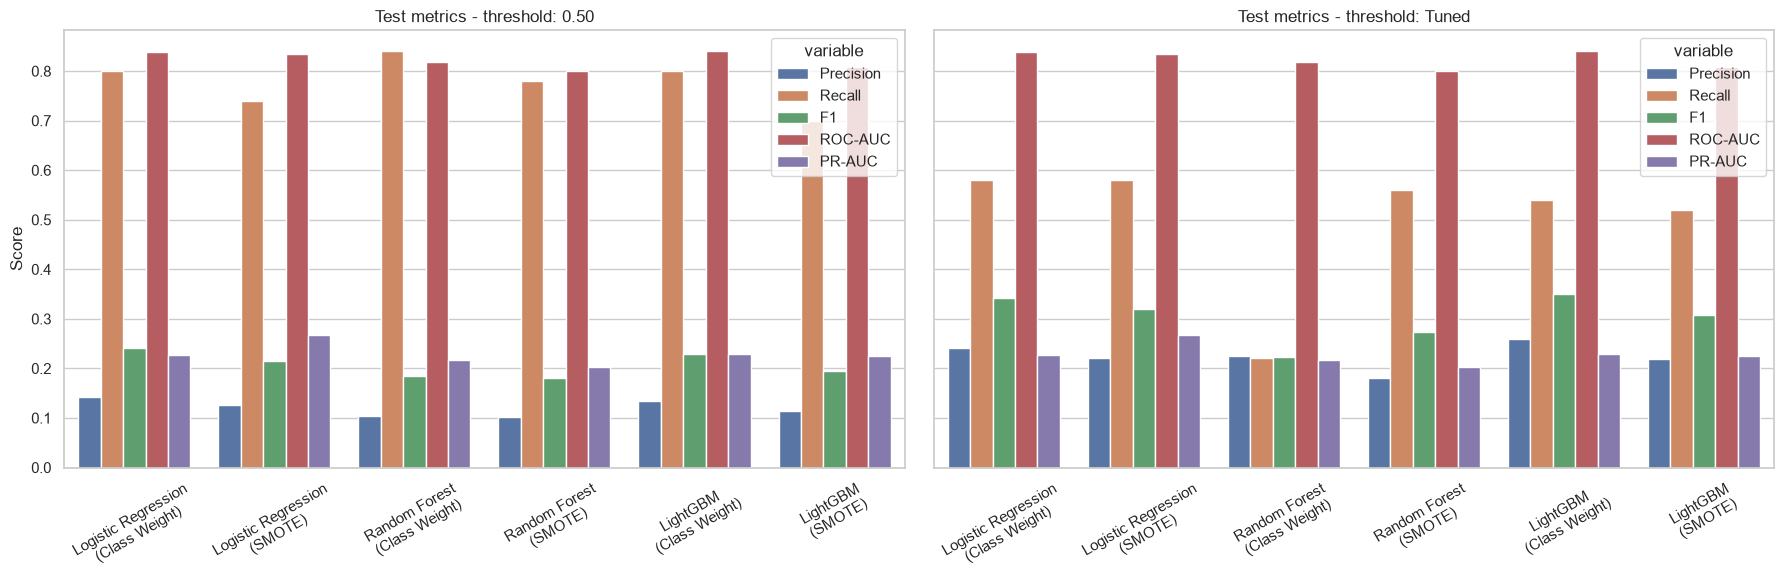

In [15]:
plot_df = results_df.copy()
plot_df["Combo"] = plot_df["Model"] + "\n(" + plot_df["Strategy"] + ")"

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
for ax, thr in zip(axes, ["0.50", "Tuned"]):
    sub = plot_df[plot_df["Threshold"] == thr].melt(
        id_vars="Combo", value_vars=["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"])
    sns.barplot(data=sub, x="Combo", y="value", hue="variable", ax=ax)
    ax.set_title(f"Test metrics - threshold: {thr}")
    ax.set_xlabel(""); ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### 8.2 ROC and Precision-Recall curves

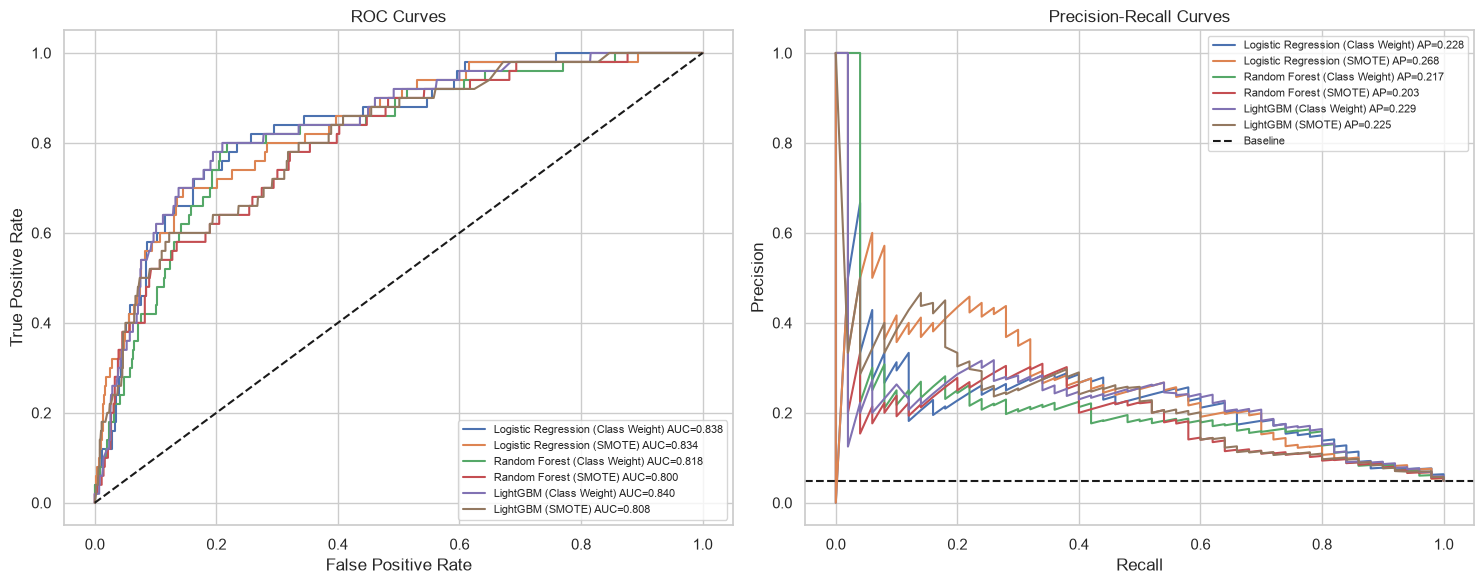

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for (m_name, s_name), proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{m_name} ({s_name}) AUC={roc_auc_score(y_test, proba):.3f}")
    p, r, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(r, p, label=f"{m_name} ({s_name}) AP={average_precision_score(y_test, proba):.3f}")
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_title("ROC Curves")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate"); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color="k", ls="--", label="Baseline"); axes[1].set_title("Precision-Recall Curves")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 9. Select the best model

In [17]:
# Best = highest F1 with tuned threshold (ties broken by PR-AUC)
tuned = results_df[results_df["Threshold"] == "Tuned"].sort_values(["F1", "PR-AUC"], ascending=False)
best_row = tuned.iloc[0]
best_key = (best_row["Model"], best_row["Strategy"])
best_pipe = fitted[best_key]
best_thr = thresholds[best_key]

print("Best model :", best_key)
print("Threshold  :", round(best_thr, 3))
print(best_row[["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]])

Best model : ('LightGBM', 'Class Weight')
Threshold  : 0.73
Precision    0.2596
Recall         0.54
F1           0.3506
ROC-AUC      0.8397
PR-AUC       0.2291
Name: 9, dtype: object


### 9.1 Confusion matrix and classification report (best model)

              precision    recall  f1-score   support

   No Stroke       0.97      0.92      0.95       972
      Stroke       0.26      0.54      0.35        50

    accuracy                           0.90      1022
   macro avg       0.62      0.73      0.65      1022
weighted avg       0.94      0.90      0.92      1022



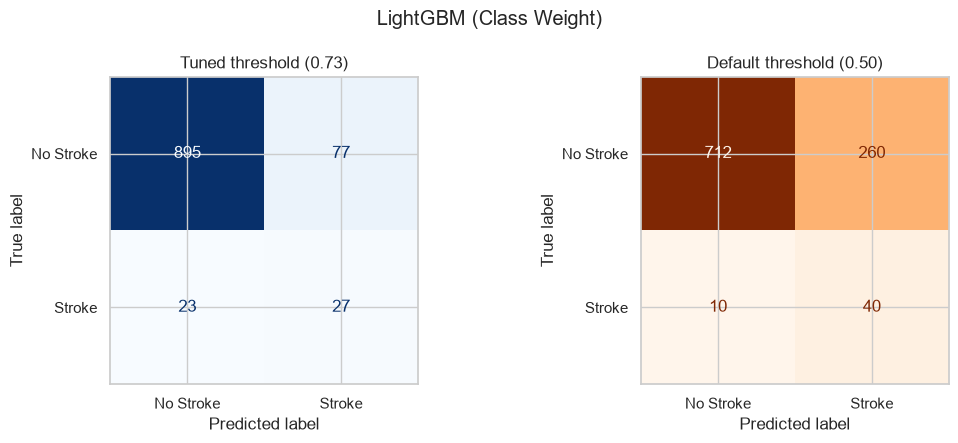

In [18]:
best_pred = (probas[best_key] >= best_thr).astype(int)

print(classification_report(y_test, best_pred, target_names=["No Stroke", "Stroke"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, best_pred), display_labels=["No Stroke", "Stroke"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Tuned threshold ({best_thr:.2f})")
default_pred = (probas[best_key] >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_test, default_pred), display_labels=["No Stroke", "Stroke"]).plot(
    ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("Default threshold (0.50)")
plt.suptitle(f"{best_key[0]} ({best_key[1]})")
plt.tight_layout()
plt.show()

## 10. Feature importance

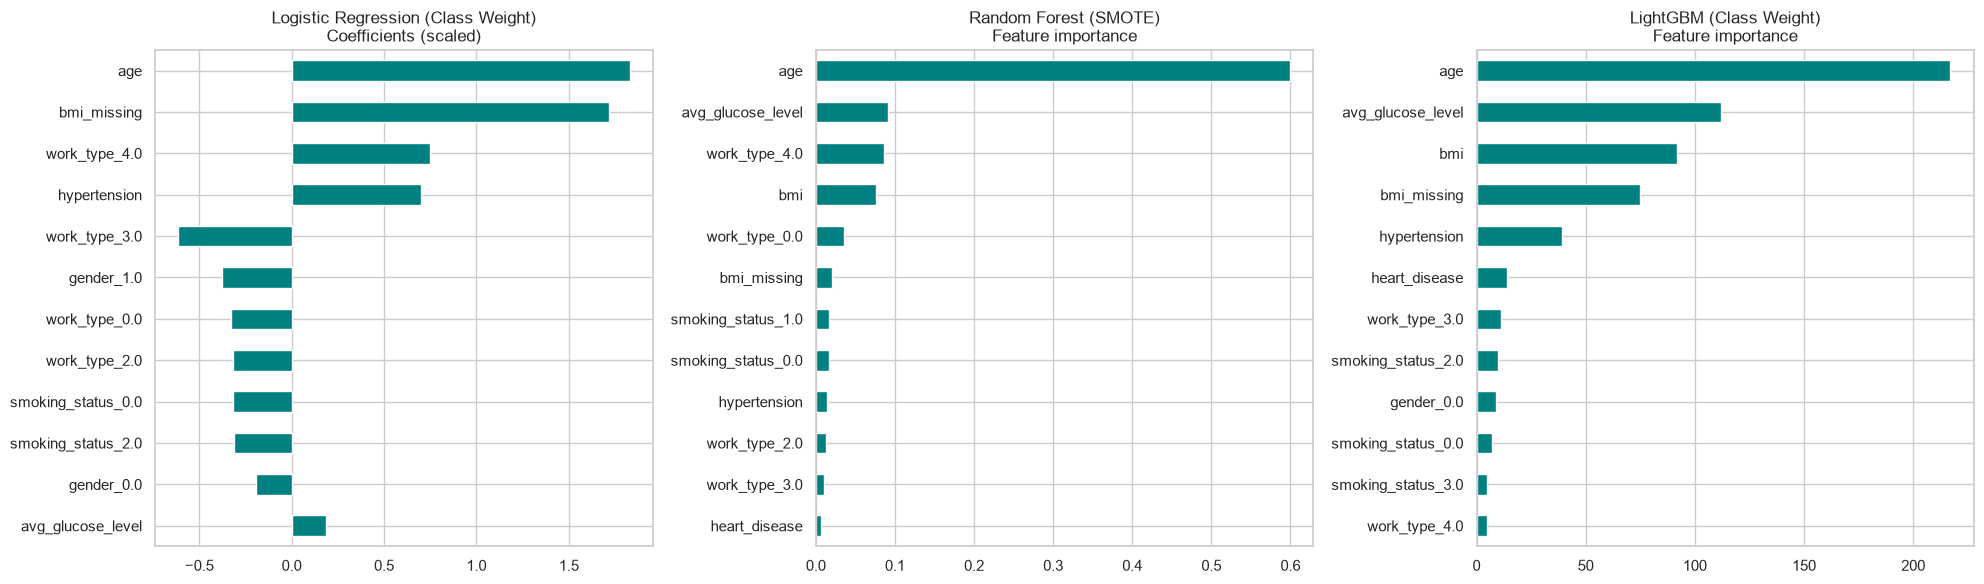

In [19]:
def get_feature_names(pipe):
    enc = pipe.named_steps["encode"]
    cat_names = enc.named_transformers_["cat"].get_feature_names_out(cat_features)
    return list(cat_names) + num_features + bin_features

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, m_name in zip(axes, models.keys()):
    # use the better strategy for each model (by tuned-threshold F1)
    sub = results_df[(results_df["Model"] == m_name) & (results_df["Threshold"] == "Tuned")]
    strat = sub.sort_values("F1", ascending=False).iloc[0]["Strategy"]
    pipe = fitted[(m_name, strat)]
    clf = pipe.named_steps["clf"]
    names = get_feature_names(pipe)

    if m_name == "Logistic Regression":
        imp = pd.Series(clf.coef_[0], index=names)
        imp = imp.reindex(imp.abs().sort_values(ascending=False).index)[:12]
        title = "Coefficients (scaled)"
    else:
        imp = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False)[:12]
        title = "Feature importance"
    imp[::-1].plot(kind="barh", ax=ax, color="teal")
    ax.set_title(f"{m_name} ({strat})\n{title}")
plt.tight_layout()
plt.show()

## 11. Final summary table

In [20]:
summary = results_df[results_df["Threshold"] == "Tuned"].drop(columns=["Threshold"]).sort_values(
    "F1", ascending=False).reset_index(drop=True)
summary

,Model,Strategy,Thr value,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,LightGBM,Class Weight,0.730,0.9022,0.2596,0.54,0.3506,0.8397,0.2291
1,Logistic Regression,Class Weight,0.762,0.8904,0.2417,0.58,0.3412,0.8385,0.2278
2,Logistic Regression,SMOTE,0.732,0.8796,0.2214,0.58,0.3204,0.8341,0.2676
3,LightGBM,SMOTE,0.732,0.8855,0.2185,0.52,0.3077,0.8078,0.2252
4,Random Forest,SMOTE,0.641,0.8542,0.1806,0.56,0.2732,0.7996,0.2026
5,Random Forest,Class Weight,0.713,0.9247,0.2245,0.22,0.2222,0.8178,0.2166


## 12. Predict stroke risk for a new patient (example)

In [21]:
new_patient = pd.DataFrame([{
    "gender": "Male", "work_type": "Private", "smoking_status": "formerly smoked",
    "hypertension": 1, "heart_disease": 0, "bmi_missing": 0,
    "age": 68, "avg_glucose_level": 210.0, "bmi": 31.5
}])[feature_order]

risk = best_pipe.predict_proba(new_patient)[0, 1]
print(f"Predicted stroke probability: {risk:.3f}")
print("Prediction:", "HIGH RISK (stroke)" if risk >= best_thr else "LOW RISK (no stroke)")

Predicted stroke probability: 0.792
Prediction: HIGH RISK (stroke)
